### ELO328 - Procesamiento Digital de Imágenes
# Clase 9: Redes Neuronales Convolucionales
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Corteza visual

Región del cerebro que recibe, integra y procesa la información visual procedente de las retinas.

David H. Hubel y Torsten Wiesel demostraron que no todas las neuronas de la corteza visual reaccionan de la misma manera. Algunas tienen un campo receptivo local pequeño y otras más grandes (detectan patrones más complejos); algunas reaccionan solo a imágenes de líneas horizontales, mientras que otras reaccionan solo a líneas con diferentes orientaciones.

<div align="center">
    <img src="img/visual_cortex.jpg" alt="" width="60%" align="center" />
</div>

# Red Neuronal Convolucional (CNN)

<div align="center">
    <img src="img/CNN.png" alt="" width="60%" align="center" />
</div>

# Operador de convolución

<div align="center">
    <img src="img/convolution.jpeg" alt="" width="40%" align="center" />
</div>

# Convolutional layer

En una capa convolucional, todas las neuronas aplican una operación de convolución, es decir, un filtro (o kernel) a los datos. El resultado se conoce como mapa de características (**Feature Map**).

<div align="center">
    <img src="img/featuremaps.png" alt="" width="40%" align="center" />
</div>

La diferencia fundamental entre una capa densamente conectada y una capa de convolución es la siguiente: las capas densas aprenden patrones globales en su espacio de características de entrada (involucran a todos los píxeles), mientras que las capas de convolución aprenden patrones locales.

# Pooling layer

- La capa de pooling es generalmente utilizada entre capas convolucionales en una arquitectura CNN.
- Es una forma de muestreo descendente no lineal (downsampling).

<div align="center">
    <img src="img/downsampling.jpg" alt="" width="20%" align="center" />
</div>

- Reduce el tamaño de la representación y por lo tanto el número de parámetros, el cómputo y el sobreajuste.

- Lo más usual es aplicar un filtro max pooling de 2x2 con stride 2, es decir, moverse a lo largo y ancho cada dos celdas seleccionando el mayor.

# Ejemplos de Pooling 2x2 con stride 2
<div align="center">
    <img src="img/pooling.png" alt="" width="40%" align="center" />
</div>

# Flatten

- "Aplana" el mapa de características obtenido después del pooling (*Pooled Feature Map*).
- Implementado como capa, en realidad lo que hace es dejar toda la entrada en una sola dimensión.
- Ideal para ser usado entre una capa *Conv* y una *Dense*.

<div align="center">
    <img src="img/flattening.png" alt="" width="40%" align="center" />
</div>

La razón por la que hacemos esto es porque vamos a necesitar insertar estos datos en una red neuronal artificial más adelante.


<div align="center">
    <img src="img/flatten.png" alt="" width="60%" align="center" />
</div>

# Capa Fully Connected

- En la capa Fully Connected (FC), también llamada capa densa (*Dense*), cada neurona recibe como entrada todas las neuronas de la capa previa y la salida es la multiplicación de los pesos por entrada.

<div align="center">
    <img src="img/fclayer.png" alt="" width="20%" align="center" />
</div>

- Las capas de convolución y pooling se utilizan para extraer características genéricas relevantes de las imágenes. La capa FC clasifica la información de alto nivel de abstracción obtenida por las capas convolucionales.

# Arquitectura Convolucional Básica (CNN)

<div align="center">
    <img src="img/arquitectura.jpg" alt="" width="90%" align="center" />
</div>

# Arquitecturas CNN más usadas

Hay varias arquitecturas de CNN disponibles que han sido clave en detección y reconocimiento de objetos:

- LeNet
- AlexNet
- GoogLeNet
- VGGNet
- ResNet
- Xception

**LeNet:** Las primeras aplicaciones exitosas de redes convolucionales fueron desarrolladas por Yann LeCun en la década de 1990. De estos, la más conocida es la arquitectura LeNet que se utilizaba para leer códigos postales, dígitos, etc.

<div align="center">
    <img src="img/lenet.jpeg" alt="" width="70%" align="center" />
</div>

**AlexNet:** El primer trabajo que popularizó las redes convolucionales en visión artificial fue AlexNet, desarrollado por Alex Krizhevsky, Ilya Sutskever y Geoff Hinton, en 2012. La red tenía una arquitectura muy similar a LeNet, pero era más profunda, más grande y presentaba capas convolucionales apiladas una encima de la otra (anteriormente, era común tener una sola capa CONV siempre seguida inmediatamente por una capa POOL). Para reducir el overfitting utilizaron dropout y data augmentation.

<div align="center">
    <img src="img/alexnet.png" alt="" width="70%" align="center" />
</div>

# Dropout

Ignorar neuronas durante la fase de entrenamiento escogidas aleatoriamente. 

<div align="center">
    <img src="img/dropout.png" alt="" width="50%" align="center" />
</div>

# Data Augmentation

Entrenar con un conjunto de entrenamiento muy grande es la mejor forma de generalizar. Si no se dispone de muchos ejemplos, se pueden aumentar aplicando filtros, rotaciones, etc.

<div align="center">
    <img src="img/augmentation.png" alt="" width="50%" align="center" />
</div>

**GoogLeNet (2014):** Su principal contribución fue el desarrollo de un módulo *Inception* que redujo drásticamente la cantidad de parámetros en la red (4M, en comparación con AlexNet con 60M). El módulo se repite en la red y procesa la entrada usando múltiples filtros en paralelo, antes de concatenar sus mapas de activación, formando la entrada de la siguiente etapa. Utiliza capas convolucionales con MaxPooling. Además, usa Average Pooling en lugar de FC. Hay varias versiones posteriores como Xception (2016).

<div align="center">
    <img src="img/googlenet.png" alt="" width="90%" align="center" />
</div>

**VGGNet (2014):** Competidora de GoogLeNet con arquitectura similar a AlexNet pero más profunda: 2 o 3 capas convolucionales, una capa de pooling, luego nuevamente 2 o 3 capas convolucionales, una capa de pooling, y así sucesivamente (con un total de solo 16 capas convolucionales), más una red densa final con 2 capas ocultas y la capa de salida. Usó solo filtros 3 × 3, pero muchos filtros.

<div align="center">
    <img src="img/VGG.png" alt="" width="60%" align="center" />
</div>

**ResNet (2015):** 152 capas con algunos saltos entre capas y un uso intensivo de Batch Normalization, implementado al final de cada capa. No usa capas densas al final de la red.

<div align="center">
    <img src="img/resnet.png" alt="" width="60%" align="center" />
</div>

# Normalización de la Entrada

- Normalizar todas las entradas a una escala estándar permite que la red aprenda más rápidamente los parámetros óptimos para cada nodo de entrada.
- Se utiliza `StandardScaler` para lograr media 0 y desviación estándar 1: $$\frac{x-\mu}{\sigma},$$ donde $\mu$ es la media y $\sigma$ la desviación estándar.
- En imágenes es común simplemente escalar por $1/255$ para que las intensidades de cada canal se encuentren en $[0,1]$.

# Batch Normalization

- La "normalización por lotes" se utiliza en casi todas las arquitecturas de CNN.

- Reduce la *Internal Covariance Shift* con el objetivo de:

    - Reducir sustancialmente el tiempo de entrenamiento.
    - Eliminar la necesidad de Dropout.
    - Disminuir la cantidad de regularización necesaria.
    - Permitir una mayor tasa de aprendizaje.

# Internal Covariate Shift

- Cambio en la distribución de las activaciones de la red debido al cambio en los parámetros de la red durante el entrenamiento.
- Cuanto más profunda sea la red, más "enredo" puede causar un cambio de covariable interna. 
- Análogo al juego del teléfono (cuanta más gente, o ‘capas’, más desordenado va a llegar el mensaje).
<div align="center">
    <img src="img/telefono.jpeg" alt="" width="30%" align="center" />
</div>

- Se busca estabilizar y mejorar la conexión entre los resultados de la capa de salida y los nodos de cada capa oculta.

# ¿Qué hace Batch Normalization?

- Ya sabemos que escalar nuestros datos (media 0 y desviación estándar 1) es esencial para cualquier modelo que estemos construyendo. En este caso, no solo se asegura que los datos se escalen antes de ingresar al entrenamiento, sino que continúen siendo escalados mientras se entrena.

- Sigue la lógica de la normalización de entradas, pero aplicado como capa de normalización en el modelo.

<div align="center">
    <img src="img/batchnorm.jpg" alt="" width="60%" align="center" />
</div>

**Xception (2016):** Variante de GoogLeNet con *Extreme Inception*, pero combinada con ResNet. Reemplaza el módulo *Inception* con un tipo espcial de capa llamada *separable convolution* que captura las formas y detalles por separado utilizando diferentes filtros.

<div align="center">
    <img src="img/separable_convolution.jpg" alt="" width="40%" align="center" />
</div>

<div align="center">
    <img src="img/comparacion.jpg" alt="" width="60%" align="center" />
</div>

Comparación del tamaño del modelo, la velocidad y la precisión entre redes previamente entrenadas de uso habitual.

# Demo CNN

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras

In [2]:
lena = keras.preprocessing.image.load_img("test/lena.jpg", target_size=(512, 512))
lena = keras.preprocessing.image.img_to_array(lena)
flor = keras.preprocessing.image.load_img("test/flor.jpg", target_size=(512, 512))
flor = keras.preprocessing.image.img_to_array(flor)

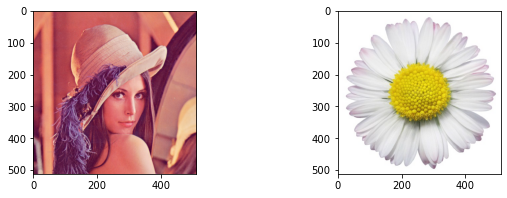

In [3]:
fig = plt.figure(figsize=(10, 3))
ax1 = fig.add_subplot(121)
plt.imshow(lena/255)
ax2 = fig.add_subplot(122)
plt.imshow(flor/255)
plt.show()

In [4]:
images = np.array([lena, flor])

In [5]:
images.shape

(2, 512, 512, 3)

# Capa Convolucional

In [6]:
conv = keras.layers.Conv2D(filters=10, kernel_size=7, strides=1,
                           padding="SAME", activation="relu")

In [7]:
conv_outputs = conv(images)

In [8]:
conv_outputs.shape 

TensorShape([2, 512, 512, 10])

In [9]:
def plot_convolutional_layer(images, conv_outputs):
    plt.figure(figsize=(20,2*images.shape[0]))
    for image_index in range(images.shape[0]):
        for feature_map_index in (range(conv_outputs.shape[3])):
            plt.subplot(images.shape[0], conv_outputs.shape[3], image_index * conv_outputs.shape[3] + feature_map_index + 1)
            plt.imshow(conv_outputs[image_index, :, :, feature_map_index], cmap="gray")
            plt.xticks([])
            plt.yticks([])
    plt.subplots_adjust(wspace=0.1, hspace=0)
    plt.show()

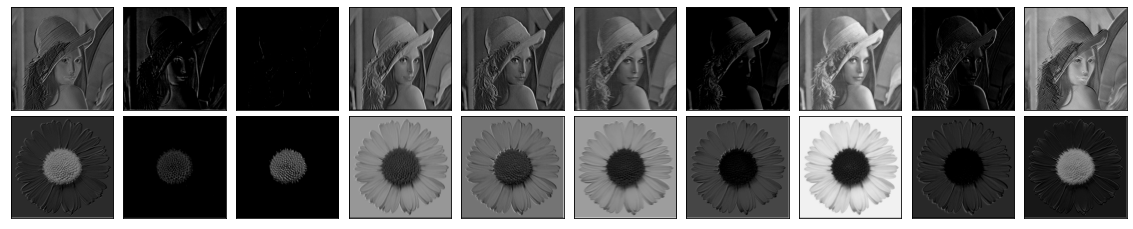

In [10]:
plot_convolutional_layer(images, conv_outputs)

# Pooling layer

In [11]:
from matplotlib import gridspec

In [12]:
def plot_maxpooling_layer(images, pool_size):
    max_pool = keras.layers.MaxPool2D(pool_size=pool_size)
    pool_output = max_pool(images)
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(4, 4), gridspec_kw=dict(width_ratios=[pool_size,1]))
    axs[0].imshow(images[0]/255)
    axs[0].set_title("Input")
    axs[1].imshow(pool_output[0]/255)
    axs[1].set_title("Output")
    plt.subplots_adjust(wspace=0.3, hspace=0)
    plt.show()

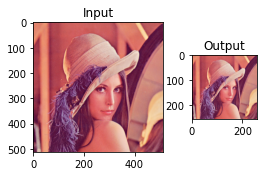

In [13]:
plot_maxpooling_layer(images, 2)

# Ejemplo del proceso en una CNN

In [14]:
def plot_cnn(images,layer,filters=10,kernel_size=7,strides=1,padding="SAME",activation="relu",pool_size=2):
    img_input = images.copy()
    for _ in range(layer):        
        conv = keras.layers.Conv2D(filters=filters, kernel_size=kernel_size, 
                                   strides=strides, padding=padding, activation=activation)
        conv_outputs = conv(img_input)        
        max_pool = keras.layers.MaxPool2D(pool_size=pool_size)
        pool_output = max_pool(img_input)
        img_input = pool_output
    plot_convolutional_layer(img_input, conv_outputs)

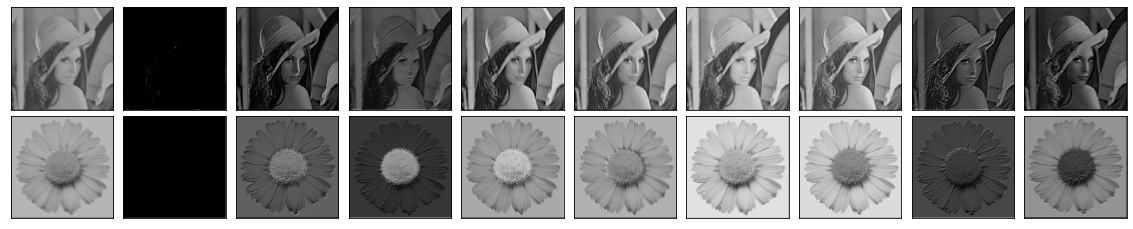

In [15]:
plot_cnn(images,1)

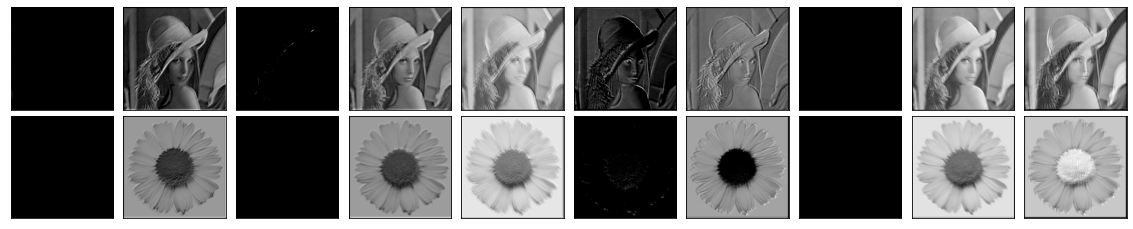

In [16]:
plot_cnn(images,2)

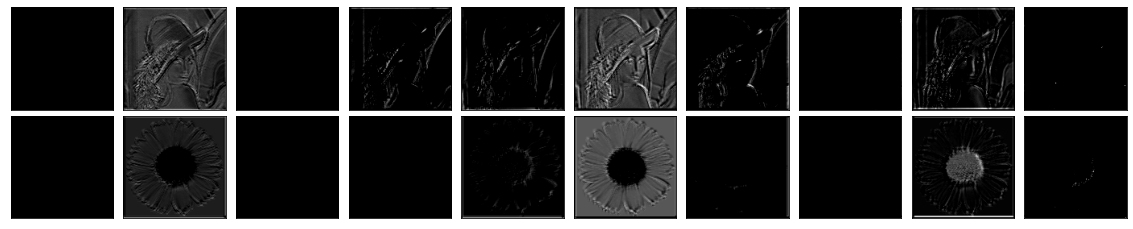

In [17]:
plot_cnn(images,3)

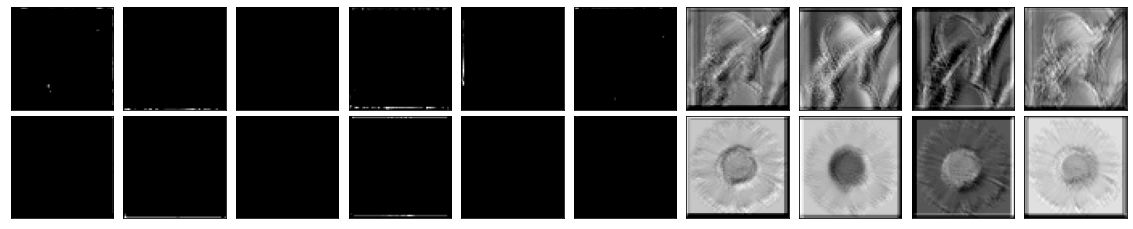

In [18]:
plot_cnn(images,4)

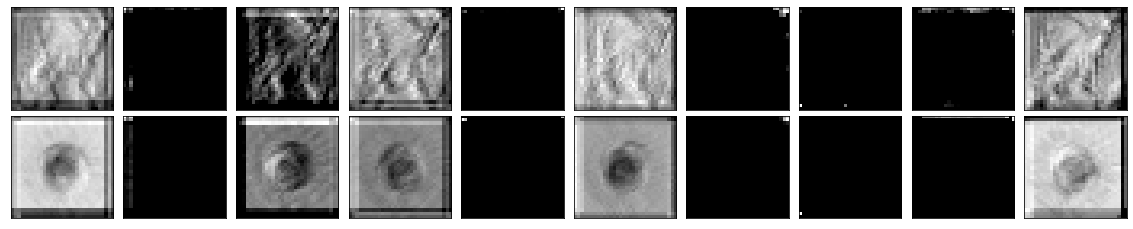

In [19]:
plot_cnn(images,5)

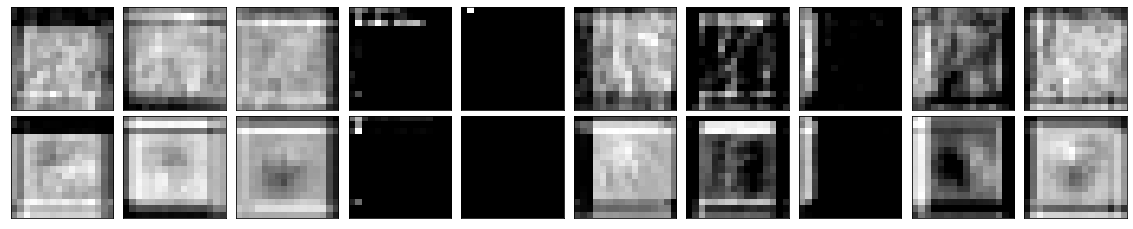

In [20]:
plot_cnn(images,6)

# Visualización de la activación de clase

Útil para comprender qué partes de una imagen dada llevaron a una convnet a su decisión final de clasificación.

In [21]:
from keras import backend as K
from skimage.transform import resize
from PIL import Image

In [22]:
from keras.applications.vgg16 import VGG16
vgg16_model = VGG16(weights='imagenet')

In [23]:
def activacion(model, path, layer="block5_conv3"):
    img = keras.preprocessing.image.load_img(path, target_size=(224, 224))
    preprocess_img = keras.preprocessing.image.img_to_array(img)
    preprocess_img = np.expand_dims(preprocess_img, axis=0)
    preprocess_img = keras.applications.vgg16.preprocess_input(preprocess_img)    
    
    conv_layer = model.get_layer(layer)
    heatmap_model = keras.models.Model([model.inputs], [conv_layer.output, model.output])

    with tf.GradientTape() as gtape:
        conv_output, predictions = heatmap_model(preprocess_img)
        loss = predictions[:, np.argmax(predictions[0])]
        grads = gtape.gradient(loss, conv_output)
        pooled_grads = K.mean(grads, axis=(0, 1, 2))
    
    top_K = keras.applications.vgg16.decode_predictions(predictions.numpy(), top=1)[0]    

    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_output), axis=-1)
    heatmap = np.maximum(heatmap, 0)
    max_heat = np.max(heatmap)
    if max_heat == 0:
        max_heat = 1e-10
    heatmap /= max_heat
    hm=np.squeeze(heatmap)
    res = resize(hm, img.size)
    
    plt.figure(figsize=(15,10))
    
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis('off')
    
    plt.subplot(1,3,2)
    plt.imshow(res)
    plt.title("Activation Heatmap")
    plt.axis('off')
    
    z = (res * 255).astype(np.uint8)
    pil_image=Image.fromarray(z).convert('RGB')
    pil_image
    
    im1 = img.convert('RGB')
    im = Image.blend(im1, pil_image, 0.8)
    plt.subplot(1,3,3)
    plt.imshow(im)
    plt.axis('off')  
    plt.title(f"{top_K[0][1]} ({round(top_K[0][2] * 100,2)}%)")
    plt.show()

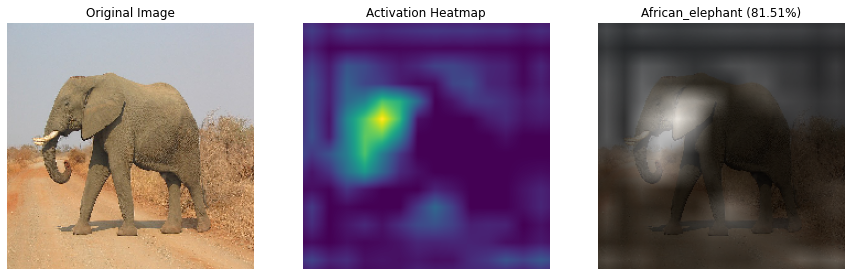

In [24]:
activacion(vgg16_model, "test/elefante.jpg")

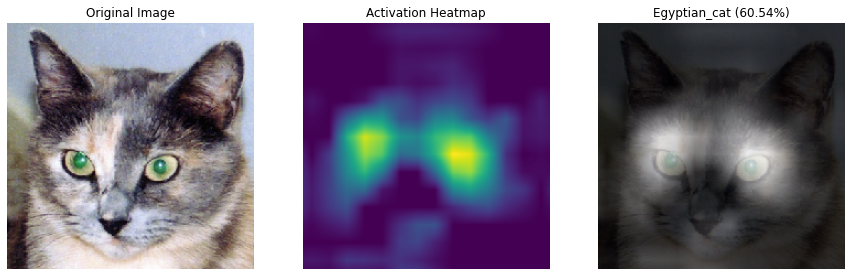

In [25]:
activacion(vgg16_model, "test/cat.jpg")

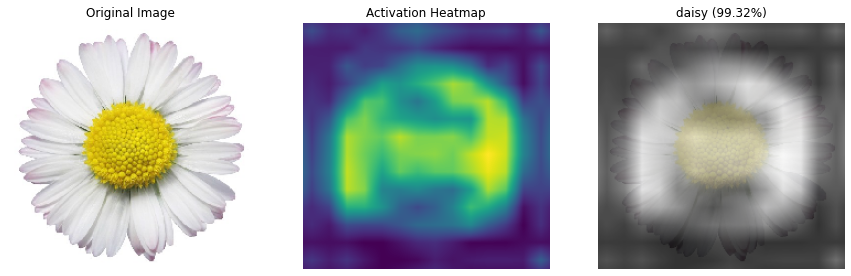

In [26]:
activacion(vgg16_model, "test/flor.jpg")